# Data Preparation and Exploratory Data Analysis

## Strategic Positioning of CIDFF

This notebook prepares and explores data from the French National Register of Associations (RNA).

The goal is to identify associations whose declared missions relate to gender-based violence, women's rights and gender equality rights across four departments: Isère (38), Rhône (69), Savoie (73), and Haute-Savoie (74).

The analysis focuses on declared missions and registered headquarters. It does not measure actual services, association activity, or local needs.

The keyword-based selection method was developed through earlier exploratory tests, documented separately in the project archive.

In [1]:
import pandas as pd
import numpy as np
import zipfile
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup

## 1. Data Loading

We load the RNA data for the four departments: Isère (38), Rhône (69), Savoie (73), and Haute-Savoie (74).

In [2]:
zip_path = "data/raw/rna_waldec_20261001.zip"
departments = ["38", "69", "73", "74"]
rna_data = {}

with zipfile.ZipFile(zip_path, "r") as archive:
    for dept in departments:
        filename = f"rna_waldec_20261001_dpt_{dept}.csv"

        with archive.open(filename) as file:
            rna_data[dept] = pd.read_csv(
                file, sep=";", encoding="utf-8", low_memory=False
            )

        print(dept, len(rna_data[dept]))
        

38 44208
69 67657
73 15483
74 24010


In [3]:
df_rna = pd.concat(rna_data.values(), ignore_index=True)

print("Total associations:", len(df_rna))
print("Dataset shape:", df_rna.shape)

Total associations: 151358
Dataset shape: (151358, 39)


## 2. Data Preparation

We select associations based on keywords found in their declared missions.

The selection covers three themes: gender-based violence, women's rights and gender equality.

In [4]:
theme_keywords = {
    "VSS_VIF": (
        r"violences?\s+(?:conjugales?|intra[- ]?familiales?|sexistes?|sexuelles?|domestiques?)"
        r"|violences?\s+(?:faites?|exercées?)\s+(?:aux|sur|contre)\s+(?:les\s+)?femmes"
        r"|violences?\s+(?:envers|contre|sur)\s+(?:les\s+)?femmes"
        r"|violences?\s+(?:de\s+genre|basées?\s+sur\s+le\s+genre)"
        r"|violences?\s+sexistes?\s+et\s+sexuelles?\s+au\s+travail"
        r"|violences?\s+au\s+sein\s+du\s+couple"
        r"|violences?\s+dans\s+le\s+couple"
        r"|f[ée]minicides?"
        r"|agressions?\s+sexuelles?"
        r"|harcèlement\s+(?:sexuel|de\s+rue)"
        r"|harcèlement\s+(?:moral|sexuel)\s+au\s+travail"
        r"|cyberharcèlement\s+sexiste"
        r"|agissements?\s+sexistes?"
        r"|sexisme\s+au\s+travail"
        r"|incestes?"
        r"|\bviols?\b"
        r"|p[ée]docriminalit[ée]"
        r"|mutilations?\s+(?:sexuelles?|g[ée]nitales?)"
        r"|excision"
        r"|mariages?\s+(?:forc[ée]s?|contraints?)"
        r"|prostitution"
        r"|exploitation\s+sexuelle"
        r"|traite\s+des\s+(?:êtres\s+humains|femmes)"
        r"|contrôle\s+coercitif"
        r"|emprise\s+(?:conjugale|psychologique)"
        r"|victimes?\s+de\s+violences?"
    ),

    "WOMEN_EQUALITY": (
        r"droits?\s+(?:des\s+femmes|de\s+la\s+femme|des\s+filles)"
        r"|égalité\s+(?:femmes?[- ,]+hommes?|hommes?[- ,]+femmes?|des\s+sexes|de\s+genre)"
        r"|égalité\s+entre\s+(?:les\s+)?(?:femmes?\s+et\s+(?:les\s+)?hommes?|hommes?\s+et\s+(?:les\s+)?femmes?)"
        r"|égalité\s+professionnelle"
        r"|inégalités?\s+(?:femmes?[- ]hommes?|de\s+genre|entre\s+les\s+sexes)"
        r"|parité\s+(?:femmes?[- ]hommes?|hommes?[- ]femmes?|politique|professionnelle)"
        r"|f[ée]minis(?:me|tes?)"
        r"|sexisme"
        r"|sexistes?"
        r"|condition\s+f[ée]minine"
        r"|[ée]mancipation\s+(?:des\s+)?femmes"
        r"|autonomisation\s+(?:des\s+)?femmes"
        r"|autonomie\s+[ée]conomique\s+des\s+femmes"
        r"|empowerment\s+(?:des\s+)?femmes"
        r"|leadership\s+f[ée]minin"
        r"|entrepreneuriat\s+f[ée]minin"
        r"|place\s+des\s+femmes"
        r"|promotion\s+des\s+droits\s+des\s+femmes"
        r"|sant[ée]\s+des\s+femmes"
        r"|sant[ée]\s+sexuelle\s+et\s+reproductive"
        r"|droits?\s+(?:sexuels?|reproductifs?)"
        r"|contraception"
        r"|interruption\s+volontaire\s+de\s+grossesse"
        r"|acc[èe]s\s+des\s+femmes\s+aux\s+droits"
        r"|discriminations?\s+(?:envers|contre|à\s+l'[ée]gard\s+des)\s+(?:les\s+)?femmes"
    )
}

In [5]:
text = df_rna["objet"].fillna("")

for theme, pattern in theme_keywords.items():
    df_rna[theme] = text.str.contains(
        pattern, case=False, na=False, regex=True
    )

df_selected = df_rna[
    df_rna[list(theme_keywords.keys())].any(axis=1)
].copy()

print("Total RNA associations:", len(df_rna))
print("Selected associations:", len(df_selected))

Total RNA associations: 151358
Selected associations: 585


In [6]:
sample = df_selected.sample(15, random_state=42)

for _, row in sample.iterrows():
    print("\nAssociation:", row["titre"])
    print("Mission:", row["objet"])
    print("Themes:", [
        theme for theme in theme_keywords if row[theme]
    ])
    print("-" * 60)


Association: ECOFÉMINA
Mission: sensibiliser sur les sujets de l'écoféminisme en luttant contre toute forme de domination sur les minorités ( genre, raciales, handicap, spéciste etc ) afin de permettre l'émancipation et la prise en compte de chacun, pour une société plus juste, inclusive, solidaire et écologiste, tout en veillant à respecter la liberté de chacune et chacun ; permettre un progrès social par des prises de conscience et de mise en lumière des problématiques rencontrées, en proposant des pistes de solutions pour initier le pouvoir d'agir ; sensibiliser sur les enjeux sociétaux et écologiques, lutter contre le racisme, le validisme, le sexisme, le spécisme, l'homophobie, grossophobie et toutes autres formes de dominations sur les personnes, animaux, la faune et la flore, afin de contribuer à réduire ou faire disparaître les fragilités et inégalités auxquelles les individus sont exposés ; mettre en lumière les solutions déjà existantes ( associations, collectifs, entreprise

In [7]:
test_missions = pd.Series([
    "Lutte contre les violences faites aux femmes",
    "Prévention des violences envers les femmes",
    "Protection des femmes victimes de violences",
    "Accompagnement des victimes de violences conjugales",
    "Prévention du viol et des agressions sexuelles"
])

for mission in test_missions:
    matched = [
        theme for theme, pattern in theme_keywords.items()
        if pd.Series([mission]).str.contains(
            pattern, case=False, regex=True
        ).iloc[0]
    ]
    print(mission, ":", matched)

Lutte contre les violences faites aux femmes : ['VSS_VIF']
Prévention des violences envers les femmes : ['VSS_VIF']
Protection des femmes victimes de violences : ['VSS_VIF']
Accompagnement des victimes de violences conjugales : ['VSS_VIF']
Prévention du viol et des agressions sexuelles : ['VSS_VIF']


In [8]:
print("VSS/VIF:", df_selected["VSS_VIF"].sum())
print("Women's rights and equality:", df_selected["WOMEN_EQUALITY"].sum())
print("Both themes:", (
    df_selected["VSS_VIF"] & df_selected["WOMEN_EQUALITY"]
).sum())

VSS/VIF: 259
Women's rights and equality: 397
Both themes: 71


In [9]:
# Extract the department code from the postal code
df_selected["department"] = (
    df_selected["adrs_codepostal"]
    .astype("string")
    .str.strip()
    .str[:2]
)

# Check the geographical distribution
print(df_selected["department"].value_counts(dropna=False))

department
69    317
38    122
74     93
73     35
42      3
75      2
94      2
13      1
72      1
26      1
12      1
59      1
11      1
43      1
87      1
92      1
54      1
46      1
Name: count, dtype: int64[pyarrow]


In [10]:
# Identify associations outside the study area
df_outside = df_selected[
    ~df_selected["department"].isin(departments)
].copy()

# Display their names, postal codes and declared missions
for _, row in df_outside.iterrows():
    print("\nAssociation:", row["titre"])
    print("Postal code:", row["adrs_codepostal"])
    print("Mission:", row["objet"])
    print("-" * 60)

print("\nTotal outside the study area:", len(df_outside))


Association: UNION NATIONALE DROITS ET DEVOIRS DE L'ENFANT (U.N.D.D.E.)
Postal code: 13440.0
Mission: regrouper en réseau les associations, fédérations organismes oeuvrant pour les droits et devoirs de l'enfant, diffuser la convention relative aux droits de l'enfant, mise en oeuvre d'actions de prévention sur la violence, la maltraitance, la mise ensituation de risques envers l'enfant, de défendre les droits de l'enfant, victime de violences, de maltraitance, de mise en danger, d'atteinte à sa dignité, d'organiser des conférences, colloques sur les droits de l'enfant
------------------------------------------------------------

Association: L' ENFANCE DE L'HUMANITE
Postal code: 72100.0
Mission: sante education lutte contre la delinquance juvenile et l excision
------------------------------------------------------------

Association: SISTA - SOLIDARITÉ INTERSECTIONNALITÉ SOINS ET TECHNIQUES D'AUTODÉFENSE
Postal code: 26190.0
Mission: promouvoir, étudier et diffuser toutes pratiques co

In [11]:
# Keep associations in the four selected departments
df_final = df_selected[
    df_selected["department"].isin(departments)
].copy()

# Check the number of associations and unique IDs
print("Associations in the study area:", len(df_final))
print("Unique RNA IDs:", df_final["id"].nunique())
print("Duplicate IDs:", df_final["id"].duplicated().sum())

Associations in the study area: 567
Unique RNA IDs: 567
Duplicate IDs: 0


In [12]:
# Count selected associations in each department
dept_counts = (
    df_final["department"]
    .value_counts()
    .sort_index()
)

print(dept_counts)

department
38    122
69    317
73     35
74     93
Name: count, dtype: int64[pyarrow]


In [13]:
# Count all RNA associations by department
rna_totals = {
    "38": 44208,
    "69": 67657,
    "73": 15483,
    "74": 24010
}

# Compare selected associations with all registered associations
dept_summary = pd.DataFrame({
    "selected": dept_counts,
    "total_rna": pd.Series(rna_totals)
})

dept_summary["selection_rate"] = (
    dept_summary["selected"] / dept_summary["total_rna"] * 100
)

print(dept_summary.round(2))

    selected  total_rna  selection_rate
38       122      44208            0.28
69       317      67657            0.47
73        35      15483            0.23
74        93      24010            0.39


### 2.1. Data Cleaning

We clean postal codes, check missing values and duplicates, and prepare the final dataset for analysis.

In [14]:
# Clean postal codes and restore leading zeros
df_selected["postal_code"] = (
    pd.to_numeric(df_selected["adrs_codepostal"], errors="coerce")
    .astype("Int64")
    .astype("string")
    .str.zfill(5)
)

# Extract department codes from cleaned postal codes
df_selected["department"] = df_selected["postal_code"].str[:2]

# Check the updated distribution
print(df_selected["department"].value_counts(dropna=False))

department
69    317
38    122
74     93
73     35
42      3
01      2
75      2
94      2
13      1
72      1
26      1
59      1
43      1
87      1
92      1
54      1
46      1
Name: count, dtype: int64[pyarrow]


In [15]:
# Keep associations located in the four study departments
df_final = df_selected[
    df_selected["department"].isin(departments)
].copy()

# Check the final dataset
print("Final dataset shape:", df_final.shape)
print("Unique RNA IDs:", df_final["id"].nunique())
print("Duplicate IDs:", df_final["id"].duplicated().sum())

Final dataset shape: (567, 43)
Unique RNA IDs: 567
Duplicate IDs: 0


In [16]:
# Check missing values in the columns used for the analysis
columns_to_check = [
    "id",
    "titre",
    "objet",
    "postal_code",
    "department",
    "adrs_libcommune",
    "adrs_codeinsee"
]

print(df_final[columns_to_check].isna().sum())

id                 0
titre              0
objet              0
postal_code        0
department         0
adrs_libcommune    0
adrs_codeinsee     0
dtype: int64


### 2.2. Final Dataset

We keep the variables needed for the analysis, including association details, location and selected themes.

### 2.2.1 Validation of the RNA thematic selection

Some well-known local organisations were missing from our thematic selection.

We will compare our selected associations with the full RNA dataset to identify possible gaps.

This step will help us evaluate the limitations of keyword-based filtering before using the data for strategic analysis.

In [17]:
print(df_rna.columns.tolist())

['id', 'id_ex', 'siret', 'rup_mi', 'gestion', 'date_creat', 'date_decla', 'date_publi', 'date_disso', 'nature', 'groupement', 'titre', 'titre_court', 'objet', 'objet_social1', 'objet_social2', 'adrs_complement', 'adrs_numvoie', 'adrs_repetition', 'adrs_typevoie', 'adrs_libvoie', 'adrs_distrib', 'adrs_codeinsee', 'adrs_codepostal', 'adrs_libcommune', 'adrg_declarant', 'adrg_complemid', 'adrg_complemgeo', 'adrg_libvoie', 'adrg_distrib', 'adrg_codepostal', 'adrg_achemine', 'adrg_pays', 'dir_civilite', 'siteweb', 'publiweb', 'observation', 'position', 'maj_time', 'VSS_VIF', 'WOMEN_EQUALITY']


In [18]:
# Request the Lyon directory page
url = "https://annuaire.arretonslesviolences.gouv.fr/search?q=Lyon&lat=45.758&lng=4.835&label=Lyon"

response = requests.get(url, timeout=20)
print("HTTP status:", response.status_code)

soup = BeautifulSoup(response.text, "html.parser")

headings = soup.find_all("h3")

print("Names found:", len(headings))
print([heading.get_text(strip=True) for heading in headings[:10]])

HTTP status: 200
Names found: 10
['Ça Démenage', 'Femmes Contre Les Intégrismes (fci)', 'Cidff Rhône - Arcalpin', 'Cidff Rhône-Arc Alpin Interdépartemental, Lyon', 'Femmes Solidaires Lyon', 'Mouvement Du Nid Rhône', 'Filactions', 'Le Mas Info Droits Victimes', 'Au Tambour !', 'Le Planning Familial - 69']


In [19]:
# Find scripts containing directory data
scripts = soup.find_all("script")

print("Total scripts:", len(scripts))

for i, script in enumerate(scripts):
    content = script.get_text()
    if "24:[" in content:
        print("Script index:", i)
        print("Script length:", len(content))
        print("Preview:", content[:200])

Total scripts: 23
Script index: 22
Script length: 499004
Preview: self.__next_f.push([1,"1:\"$Sreact.fragment\"\n2:I[494771,[\"/_next/static/chunks/2qfuupshon4-r.js\",\"/_next/static/chunks/1bqbc95eq9etw.js\",\"/_next/static/chunks/0x1og22pd267d.js\",\"/_next/static


In [20]:
import json

# Decode the embedded directory data
script_content = scripts[22].get_text()

raw_data = script_content.split(
    "self.__next_f.push([1,", 1
)[1].rsplit("])", 1)[0]

decoded_data = json.loads(raw_data)

print("Decoded data length:", len(decoded_data))
print("Association marker found:", "24:[" in decoded_data)

Decoded data length: 452226
Association marker found: True


In [21]:
# Extract association records
start = decoded_data.find("24:[") + len("24:")

associations, end = json.JSONDecoder().raw_decode(
    decoded_data[start:]
)

print("Number of associations:", len(associations))
print("First association:", associations[0]["name"])

Number of associations: 839
First association: Cidff Allier, Moulins


In [22]:
# Create the directory DataFrame
df_directory = pd.DataFrame(associations)

print("Total records:", len(df_directory))
print("\nAvailable columns:")
print(df_directory.columns.tolist())

Total records: 839

Available columns:
['name', 'sourceRef', 'email', 'phone', 'phoneSecondary', 'website', 'address', 'addressComplement', 'postalCode', 'city', 'latitude', 'longitude', 'key', 'violenceTypes', 'id', 'sourceName']


In [23]:
# Filter directory records by department
departments = ["38", "69", "73", "74"]

df_directory["postalCode"] = (
    df_directory["postalCode"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df_territory = df_directory[
    df_directory["postalCode"].str[:2].isin(departments)
].copy()

print("Records in our territory:", len(df_territory))

print("\nRecords by department:")
print(df_territory["postalCode"].str[:2].value_counts().sort_index())

print("\nMissing postal codes in full directory:")
print((df_directory["postalCode"] == "").sum())

Records in our territory: 39

Records by department:
postalCode
38    16
69    13
73     6
74     4
Name: count, dtype: int64

Missing postal codes in full directory:
152


In [24]:
# Check missing postal codes and GPS coordinates
df_missing_postal = df_directory[
    df_directory["postalCode"] == ""
].copy()

print("Records without postal code:", len(df_missing_postal))

print(
    "Records with GPS coordinates:",
    df_missing_postal[["latitude", "longitude"]]
    .notna()
    .all(axis=1)
    .sum()
)

Records without postal code: 152
Records with GPS coordinates: 105


In [25]:
# Check cities for records without postal codes
print(
    df_missing_postal["city"]
    .value_counts()
    .head(20)
)

Series([], Name: count, dtype: int64)


In [26]:
# Check GPS coordinate types and sample values
print(df_missing_postal[["latitude", "longitude"]].dtypes)

print(
    df_missing_postal[["name", "latitude", "longitude"]]
    .dropna(subset=["latitude", "longitude"])
    .head(5)
)

latitude     float64
longitude    float64
dtype: object
                               name   latitude  longitude
101  Oppelia - Chrs Les Buissonnets  48.694667   2.164531
102          Accueil Service Évreux  49.082400   1.476558
103          Accueil Service Évreux  49.160734   1.333410
104                          Adalea  48.176274  -2.752021
105            Solidarité Femmes 46  44.503922   1.187069


In [27]:
# Identify GPS records potentially located in our study area
df_gps_candidates = df_missing_postal[
    df_missing_postal["latitude"].between(44.5, 46.5)
    & df_missing_postal["longitude"].between(4.0, 7.0)
].copy()

print("Potential records in our study area:", len(df_gps_candidates))

print(
    df_gps_candidates[["name", "latitude", "longitude"]]
    .to_string(index=False)
)

Potential records in our study area: 16
                                      name  latitude  longitude
                                Filactions 45.773409   4.836649
                               Pluri-Elles 45.167963   5.729511
              Issue De Secours - Le Rialto 45.172007   5.726342
                                      Alpa 45.584866   5.272324
                              Au Tambour ! 45.776425   4.850114
              Solidarité Femmes Beaujolais 46.045080   4.509276
                         Viffil Sos Femmes 45.760305   4.886646
Les Chouettes - Solidarité Femmes Du Diois 44.755069   5.368301
                               Ça Demenage 45.566560   5.920330
                               Ça Démenage 45.767794   4.836606
               Sos Violences Conjugales 42 46.035040   4.063806
                               Ça Démenage 45.184644   5.724543
       Femmes Contre Les Intégrismes (fci) 45.767798   4.836602
                          Savoie De Femmes 45.574651   5.922215


In [28]:
# Check departments using GPS coordinates
def get_department(row):
    url = "https://api-adresse.data.gouv.fr/reverse/"

    params = {
        "lat": row["latitude"],
        "lon": row["longitude"]
    }

    try:
        response = requests.get(url, params=params, timeout=10)
        response.raise_for_status()

        features = response.json().get("features", [])

        if features:
            postcode = features[0]["properties"].get("postcode", "")
            return postcode[:2]

    except requests.RequestException:
        pass

    return None


df_gps_candidates["department"] = df_gps_candidates.apply(
    get_department, axis=1
)

print(
    df_gps_candidates[["name", "department"]]
    .to_string(index=False)
)

                                      name department
                                Filactions         69
                               Pluri-Elles         38
              Issue De Secours - Le Rialto         38
                                      Alpa         38
                              Au Tambour !         69
              Solidarité Femmes Beaujolais         69
                         Viffil Sos Femmes         69
Les Chouettes - Solidarité Femmes Du Diois         26
                               Ça Demenage         73
                               Ça Démenage         69
               Sos Violences Conjugales 42         42
                               Ça Démenage         38
       Femmes Contre Les Intégrismes (fci)         69
                          Savoie De Femmes         73
                    Cultivons La Confiance         07
                 Espace Femmes Geneviève.d         74


In [29]:
# Keep GPS records confirmed in our four departments
departments = ["38", "69", "73", "74"]

df_gps_territory = df_gps_candidates[
    df_gps_candidates["department"].isin(departments)
].copy()

# Add the department to records identified by postal code
df_territory["department"] = df_territory["postalCode"].str[:2]

# Combine both groups
df_directory_territory = pd.concat(
    [df_territory, df_gps_territory],
    ignore_index=True
)

print("Total territorial records:", len(df_directory_territory))

print("\nRecords by department:")
print(df_directory_territory["department"].value_counts().sort_index())

print("\nDuplicate IDs:", df_directory_territory["id"].duplicated().sum())

Total territorial records: 52

Records by department:
department
38    20
69    19
73     8
74     5
Name: count, dtype: int64

Duplicate IDs: 0


In [30]:
# Explore directory records in the Rhône
df_rhone_directory = df_directory_territory[
    df_directory_territory["department"] == "69"
].copy()

print(
    df_rhone_directory[
        ["name", "city", "postalCode", "sourceName"]
    ].sort_values("name").to_string(index=False)
)

                                          name                   city postalCode                                   sourceName
                  Amicale Du Nid Dans Le Rhône                   Lyon      69007                               Amicale du Nid
                                  Au Tambour !                    NaN                 Fédération Nationale Solidarités Femmes
                        Cidff Rhône - Arcalpin                   Lyon      69001               Fédération Nationale des CIDFF
Cidff Rhône-Arc Alpin Interdépartemental, Lyon                   Lyon      69001               Fédération Nationale des CIDFF
           Femmes Contre Les Intégrismes (fci)                    NaN                 Fédération Nationale Solidarités Femmes
                   Femmes Solidaires Chaponost              Chaponost      69630                            Femmes Solidaires
                        Femmes Solidaires Lyon                   Lyon      69003                            Femmes Sol

In [31]:
import unicodedata

# Normalize names for comparison
def normalize_name(name):
    if pd.isna(name):
        return ""

    name = str(name).lower().strip()
    name = "".join(
        char for char in unicodedata.normalize("NFKD", name)
        if not unicodedata.combining(char)
    )
    return " ".join(name.split())


df_final["name_clean"] = df_final["titre"].apply(normalize_name)

df_directory_territory["name_clean"] = (
    df_directory_territory["name"].apply(normalize_name)
)

print("RNA records:", len(df_final))
print("Directory records:", len(df_directory_territory))

RNA records: 567
Directory records: 52


In [32]:
# Find exact name matches within the same department
df_matches = df_directory_territory.merge(
    df_final[["titre", "department", "name_clean"]],
    on=["name_clean", "department"],
    how="inner"
)

print("Exact matches:", len(df_matches))

print(
    df_matches[["name", "titre", "department"]]
    .to_string(index=False)
)

Exact matches: 3
                        name                        titre department
                  Filactions                   FILACTIONS         69
Solidarité Femmes Beaujolais SOLIDARITÉ FEMMES BEAUJOLAIS         69
                 Ça Démenage                  ÇA DÉMÉNAGE         38


In [33]:
# Identify directory records without an exact RNA match
rna_keys = df_final[["name_clean", "department"]].drop_duplicates()

df_unmatched = df_directory_territory.merge(
    rna_keys,
    on=["name_clean", "department"],
    how="left",
    indicator=True
)

df_unmatched = df_unmatched[
    df_unmatched["_merge"] == "left_only"
].copy()

print("Records without exact match:", len(df_unmatched))

print(
    df_unmatched[["name", "department"]]
    .sort_values(["department", "name"])
    .to_string(index=False)
)

Records without exact match: 49
                                          name department
                                          Alpa         38
                                          Alpa         38
                   Amicale Du Nid Dans L'Isère         38
                                    Femmes Sdf         38
                   France Victimes 38 - Apress         38
                      France Victimes 38 Avnir         38
                      France Victimes Grenoble         38
                                          Isis         38
                  Issue De Secours - Le Rialto         38
     Le Groupe Local Du Planning Familial - 38         38
     Le Groupe Local Du Planning Familial - 38         38
     Le Groupe Local Du Planning Familial - 38         38
     Le Groupe Local Du Planning Familial - 38         38
     Le Groupe Local Du Planning Familial - 38         38
     Le Groupe Local Du Planning Familial - 38         38
                     Le Planning Familia

In [34]:
# Check the full RNA dataset before matching
print("Full RNA records:", len(df_rna))
print("Available columns:", df_rna.columns.tolist())

Full RNA records: 151358
Available columns: ['id', 'id_ex', 'siret', 'rup_mi', 'gestion', 'date_creat', 'date_decla', 'date_publi', 'date_disso', 'nature', 'groupement', 'titre', 'titre_court', 'objet', 'objet_social1', 'objet_social2', 'adrs_complement', 'adrs_numvoie', 'adrs_repetition', 'adrs_typevoie', 'adrs_libvoie', 'adrs_distrib', 'adrs_codeinsee', 'adrs_codepostal', 'adrs_libcommune', 'adrg_declarant', 'adrg_complemid', 'adrg_complemgeo', 'adrg_libvoie', 'adrg_distrib', 'adrg_codepostal', 'adrg_achemine', 'adrg_pays', 'dir_civilite', 'siteweb', 'publiweb', 'observation', 'position', 'maj_time', 'VSS_VIF', 'WOMEN_EQUALITY']


In [35]:
# Search for key actors in the full RNA dataset
keywords = "VIFFIL|VIFFILAVI|LE MAS|TANDEM"

df_check = df_rna[
    df_rna["titre"].str.contains(
        keywords, case=False, na=False, regex=True
    )
].copy()

print("Records found:", len(df_check))

print(
    df_check[
        ["id", "titre", "adrs_libcommune", "position", "VSS_VIF", "WOMEN_EQUALITY"]
    ].to_string(index=False)
)

Records found: 29
        id                                                                                                   titre    adrs_libcommune position  VSS_VIF  WOMEN_EQUALITY
W381001413                                                                     CLUB CANIN SOUS LE MASSIF VERCUSIEN     Veurey-Voroize        A    False           False
W381004484                                                                           LE MAS ALTERNATIF DES SAVOIRS      Saint-Lattier        A    False           False
W381005749                                                        AMICALE DES PERSONNELS DU COLLEGE LE MASSEGU VIF                Vif        A    False           False
W381011332                                                                               TANDEM-HANDICAPES-VALIDES           Grenoble        D    False           False
W381023770                                                                                                  TANDEM           Grenoble        A

In [36]:
# Examine the statutory descriptions of two known actors
known_ids = ["W691052178", "W691053567"]

df_known_actors = df_rna[
    df_rna["id"].isin(known_ids)
]

for _, row in df_known_actors.iterrows():
    print("\nAssociation:", row["titre"])
    print("RNA ID:", row["id"])
    print("Statutory purpose:", row["objet"])
    print("-" * 60)


Association: VIFFIL-SOS FEMMES (VIOLENCES INTRA FAMILIALES FEMMES INFORMATIONS LIBERTÉS - SOS FEMMES)
RNA ID: W691052178
Statutory purpose: Repondre aux besoins sociaux exigeant une intervention urgente écouter, informer, accompagner des personnes victimes
------------------------------------------------------------

Association: LE MAS (LE MOUVEMENT D'ACTION SOCIALE )
RNA ID: W691053567
Statutory purpose: accueil, accompagnement et aide aux personnes en situation de victime, de souffrance psycho-sociale, de précarité ou d'exclusion ; recherche et sensibilisation sur les problématiques des publics concernés
------------------------------------------------------------


In [37]:
# Create a working table for matching
df_matching = df_directory_territory[
    ["id", "name", "department", "postalCode", "city", "sourceName", "name_clean"]
].copy()

# Rename columns to distinguish directory data from RNA data
df_matching = df_matching.rename(columns={
    "id": "directory_id",
    "name": "directory_name"
})

print("Records to match:", len(df_matching))
print(df_matching.head())

Records to match: 52
   directory_id                                  directory_name department  \
0            88                          Cidff Rhône - Arcalpin         69   
1            89  Cidff Rhône-Arc Alpin Interdépartemental, Lyon         69   
2           756                        France Victimes Grenoble         38   
3           757                     France Victimes 38 - Apress         38   
4           758                        France Victimes 38 Avnir         38   

  postalCode              city                      sourceName  \
0      69001              Lyon  Fédération Nationale des CIDFF   
1      69001              Lyon  Fédération Nationale des CIDFF   
2      38000          Grenoble                 France Victimes   
3      38200            Vienne                 France Victimes   
4      38300  Bourgoin-Jallieu                 France Victimes   

                                       name_clean  
0                          cidff rhone - arcalpin  
1  cidff 

In [38]:
# Prepare the full RNA for matching
df_rna_lookup = df_rna[
    ["id", "titre", "adrs_codepostal", "position"]
].copy()

df_rna_lookup["name_clean"] = (
    df_rna_lookup["titre"].apply(normalize_name)
)

df_rna_lookup["department"] = (
    df_rna_lookup["adrs_codepostal"]
    .astype("string")
    .str[:2]
)

# Find exact matches within the same department
df_full_matches = df_matching.merge(
    df_rna_lookup,
    on=["name_clean", "department"],
    how="inner"
)

print("Exact matches in full RNA:", len(df_full_matches))

print(
    df_full_matches[
        ["directory_name", "titre", "id", "department", "position"]
    ].to_string(index=False)
)

Exact matches in full RNA: 9
              directory_name                        titre         id department position
    France Victimes 38 Avnir     FRANCE VICTIMES 38 AVNIR W382004182         38        A
                      Tandem                       TANDEM W691088779         69        D
                      Tandem                       TANDEM W691105894         69        A
                  Femmes Sdf                   FEMMES SDF W381003284         38        A
                  Filactions                   FILACTIONS W691056885         69        A
                 Pluri-Elles                  PLURI-ELLES W382004030         38        A
                Au Tambour !                 AU TAMBOUR ! W691100483         69        A
Solidarité Femmes Beaujolais SOLIDARITÉ FEMMES BEAUJOLAIS W692010307         69        A
                 Ça Démenage                  ÇA DÉMÉNAGE W381025373         38        A


In [39]:
# Check directory records matching multiple RNA associations
match_counts = (
    df_full_matches
    .groupby(["directory_id", "directory_name"])
    .agg(
        rna_matches=("id", "nunique"),
        active_matches=("position", lambda x: (x == "A").sum())
    )
    .reset_index()
)

print("Directory records with exact matches:", len(match_counts))

print("\nRecords with multiple RNA matches:")
print(
    match_counts[match_counts["rna_matches"] > 1]
    .to_string(index=False)
)

Directory records with exact matches: 8

Records with multiple RNA matches:
 directory_id directory_name  rna_matches  active_matches
          808         Tandem            2               1


In [40]:
from difflib import get_close_matches

# Find potential RNA matches for directory records
rna_names = df_rna_lookup["name_clean"].dropna().unique().tolist()

df_matching["suggested_match"] = df_matching["name_clean"].apply(
    lambda name: get_close_matches(
        name, rna_names, n=1, cutoff=0.75
    )
)

df_matching["suggested_match"] = df_matching["suggested_match"].apply(
    lambda matches: matches[0] if matches else None
)

print(
    df_matching[
        ["directory_name", "department", "suggested_match"]
    ].to_string(index=False)
)

                                directory_name department                             suggested_match
                        Cidff Rhône - Arcalpin         69                                         NaN
Cidff Rhône-Arc Alpin Interdépartemental, Lyon         69                                         NaN
                      France Victimes Grenoble         38                       dance addict grenoble
                   France Victimes 38 - Apress         38                    france victimes 38 avnir
                      France Victimes 38 Avnir         38                    france victimes 38 avnir
                   Le Mas Info Droits Victimes         69                                         NaN
                  Viffilavi France Victimes 69         69                                         NaN
                                        Tandem         69                                      tandem
                               Avij Des Savoie         73                         

In [41]:
# Check validated RNA actors
known_ids = [
    "W691052178",  # VIFFIL-SOS Femmes
    "W691053567",  # Le MAS
    "W691064303"   # CIDFF Rhône
]

df_verified = df_rna[
    df_rna["id"].isin(known_ids)
][["id", "titre", "position"]].copy()

print(df_verified.to_string(index=False))

        id                                                                                                                                            titre position
W691052178                                                         VIFFIL-SOS FEMMES (VIOLENCES INTRA FAMILIALES FEMMES INFORMATIONS LIBERTÉS - SOS FEMMES)        A
W691053567                                                                                                          LE MAS (LE MOUVEMENT D'ACTION SOCIALE )        A
W691064303 CENTRE D'INFORMATION SUR LES DROITS DES FEMMES ET DES FAMILLES RHÔNE - ARC ALPIN INTERDÉPARTEMENTAL (CIDFF RHÔNE - ARC ALPIN INTERDÉPARTEMENTAL)        A


In [42]:
# Find potential duplicates in the directory
df_duplicates = df_directory_territory[
    df_directory_territory.duplicated(
        subset=["name_clean", "department"],
        keep=False
    )
].sort_values(["department", "name_clean"])

print("Potential duplicate records:", len(df_duplicates))

print(
    df_duplicates[
        ["id", "name", "department", "address", "latitude", "longitude"]
    ].to_string(index=False)
)

Potential duplicate records: 12
  id                                      name department                                           address  latitude  longitude
1482                                      Alpa         38                                  Bourgoin-Jallieu 45.597957   5.266993
 211                                      Alpa         38                                               NaN 45.584866   5.272324
1126 Le Groupe Local Du Planning Familial - 38         38      1 Place de la Commune de 1871 38100 Grenoble 45.179377   5.744932
1169 Le Groupe Local Du Planning Familial - 38         38 14 Place Albert Schweitzer 38300 Bourgoin-Jallieu 45.589650   5.276792
1171 Le Groupe Local Du Planning Familial - 38         38                   29 Rue Victor Hugo 38320 Eybens 45.158713   5.750927
1173 Le Groupe Local Du Planning Familial - 38         38            rue du 19 mars 1962 38120 Saint-Égrève 45.224625   5.689826
1775 Le Groupe Local Du Planning Familial - 38         38        

In [43]:
# Search active RNA associations by name
keywords = r"ALPA|PLANNING FAMILIAL|AVIJ"

df_check_ids = df_rna[
    (df_rna["position"] == "A")
    & df_rna["titre"].str.contains(
        keywords, case=False, na=False, regex=True
    )
]

print(
    df_check_ids[
        ["id", "titre", "adrs_libcommune", "adrs_codepostal"]
    ].to_string(index=False)
)

        id                                                                                                                                            titre           adrs_libcommune  adrs_codepostal
W381000612                                                                            ASSOCIATION DE LOISIRS ET DE PROMOTION DES ACTIVITES SOCIALES (ALPAS)                  Grenoble          38100.0
W381002217                                                              MOUVEMENT FRANCAIS POUR LE PLANNING FAMILIAL, ASSOCIATION DEPARTEMENTALE DE L'ISERE                  Grenoble          38000.0
W381002289                                                                                                                FEDERATION DES ALPAGES DE L'ISERE                    Adrets          38190.0
W381008003                                                                                                                                        ALPAZUR38                  Grenoble          38000.0
W3810

In [44]:
# Keep one record per organization and department.
# When several records have the same name, keep the first one.
# This is a practical choice, not a verified head office selection.
# The retained address may be a service location, not the head office.
# RNA head office information will be preferred when available.

df_directory_clean = (
    df_directory_territory
    .sort_values("id")
    .drop_duplicates(
        subset=["name_clean", "department"],
        keep="first"
    )
    .copy()
)

print("Before:", len(df_directory_territory))
print("After:", len(df_directory_clean))
print("Removed:", len(df_directory_territory) - len(df_directory_clean))

Before: 52
After: 44
Removed: 8


In [45]:
# Check which directory organizations are already in the RNA selection
# Match by normalized name and department
# A missing match does not prove that the organization is absent from RNA

df_overlap = df_directory_clean.merge(
    df_final[["id", "titre", "department"]].assign(
        name_clean=lambda df: df["titre"].apply(normalize_name)
    ),
    on=["name_clean", "department"],
    how="left",
    suffixes=("_directory", "_rna")
)

print("Already in RNA selection:", df_overlap["id_rna"].notna().sum())
print("Not matched:", df_overlap["id_rna"].isna().sum())

print(
    df_overlap[
        ["name", "department", "id_rna", "titre"]
    ].to_string(index=False)
)

Already in RNA selection: 3
Not matched: 41
                                          name department     id_rna                        titre
                        Cidff Rhône - Arcalpin         69        NaN                          NaN
Cidff Rhône-Arc Alpin Interdépartemental, Lyon         69        NaN                          NaN
                                    Filactions         69 W691056885                   FILACTIONS
                                   Pluri-Elles         38        NaN                          NaN
                  Issue De Secours - Le Rialto         38        NaN                          NaN
                                          Alpa         38        NaN                          NaN
                                  Au Tambour !         69        NaN                          NaN
                  Solidarité Femmes Beaujolais         69 W692010307 SOLIDARITÉ FEMMES BEAUJOLAIS
                             Viffil Sos Femmes         69        NaN      

In [46]:
# Remove directory records already matched in df_final
# Keep df_final unchanged for now

df_to_check = df_overlap[
    df_overlap["id_rna"].isna()
].copy()

print("Records to check:", len(df_to_check))
print("Unique directory IDs:", df_to_check["id_directory"].nunique())

Records to check: 41
Unique directory IDs: 41


In [47]:
# Search the 41 remaining organizations in the full RNA dataset
# Match by normalized name and department
# Keep df_final unchanged for now

df_rna_matches = df_to_check.merge(
    df_rna_lookup[
        ["id", "titre", "name_clean", "department", "position"]
    ],
    on=["name_clean", "department"],
    how="left",
    suffixes=("_directory", "_rna")
)

df_found = df_rna_matches[
    df_rna_matches["id_rna"].notna()
].copy()

print("RNA matches found:", len(df_found))
print("Unique directory records matched:", df_found["id_directory"].nunique())

# Display exact matches found in the full RNA dataset
print(
    df_found[
        ["name", "department", "id_rna", "titre_rna", "position"]
    ].to_string(index=False)
)

RNA matches found: 0
Unique directory records matched: 0
Empty DataFrame
Columns: [name, department, id_rna, titre_rna, position]
Index: []


In [48]:
# Check previously identified RNA organizations
# Do not add records to df_final yet

known_ids = [
    "W691052178",  # VIFFIL
    "W691053567",  # Le MAS
    "W381002217",  # Planning Familial Isere
    "W691064303",  # CIDFF Rhone
]

df_known_matches = df_rna[
    df_rna["id"].isin(known_ids)
].copy()

df_known_matches["already_in_final"] = (
    df_known_matches["id"].isin(df_final["id"])
)

print(
    df_known_matches[
        ["id", "titre", "position", "already_in_final"]
    ].to_string(index=False)
)

        id                                                                                                                                            titre position  already_in_final
W381002217                                                              MOUVEMENT FRANCAIS POUR LE PLANNING FAMILIAL, ASSOCIATION DEPARTEMENTALE DE L'ISERE        A              True
W691052178                                                         VIFFIL-SOS FEMMES (VIOLENCES INTRA FAMILIALES FEMMES INFORMATIONS LIBERTÉS - SOS FEMMES)        A             False
W691053567                                                                                                          LE MAS (LE MOUVEMENT D'ACTION SOCIALE )        A             False
W691064303 CENTRE D'INFORMATION SUR LES DROITS DES FEMMES ET DES FAMILLES RHÔNE - ARC ALPIN INTERDÉPARTEMENTAL (CIDFF RHÔNE - ARC ALPIN INTERDÉPARTEMENTAL)        A              True


In [49]:
from difflib import get_close_matches

# Search for similar names in the full RNA dataset
# Compare organizations within the same department
# Suggested matches must be checked before adding records

df_rna_active = df_rna_lookup[
    df_rna_lookup["position"] == "A"
].copy()

def suggest_rna_match(row):
    candidates = df_rna_active[
        df_rna_active["department"] == row["department"]
    ]["name_clean"].dropna().unique()

    matches = get_close_matches(
        row["name_clean"],
        candidates,
        n=1,
        cutoff=0.7
    )

    return matches[0] if matches else None

df_to_check["suggested_match"] = df_to_check.apply(
    suggest_rna_match, axis=1
)

print(
    df_to_check[
        ["name", "department", "suggested_match"]
    ].to_string(index=False)
)

                                          name department                                 suggested_match
                        Cidff Rhône - Arcalpin         69                                             NaN
Cidff Rhône-Arc Alpin Interdépartemental, Lyon         69                                             NaN
                                   Pluri-Elles         38                                     pluri-elles
                  Issue De Secours - Le Rialto         38                                             NaN
                                          Alpa         38                                           alpha
                                  Au Tambour !         69                                    au tambour !
                             Viffil Sos Femmes         69                                             NaN
                                   Ça Demenage         73                                             NaN
                                   Ça Démenage

In [50]:
# Display RNA IDs for the suggested matches
# These are suggestions, not confirmed matches
# Keep df_final unchanged

df_suggestions = df_to_check[
    df_to_check["suggested_match"].notna()
].merge(
    df_rna_active[
        ["id", "titre", "name_clean", "department", "position"]
    ],
    left_on=["suggested_match", "department"],
    right_on=["name_clean", "department"],
    how="left",
    suffixes=("_directory", "_rna")
)

# Display RNA IDs for the suggested matches
# Suggestions must be checked before adding records

print(
    df_suggestions[
        ["name", "department", "titre_rna", "id", "position"]
    ].to_string(index=False)
)

                                     name department                                       titre_rna         id position
                              Pluri-Elles         38                                     PLURI-ELLES W382004030        A
                                     Alpa         38                                           ALPHA W381000938        A
                             Au Tambour !         69                                    AU TAMBOUR ! W691100483        A
                              Ça Démenage         69                                        CAMERAGE W691060154        A
      Femmes Contre Les Intégrismes (fci)         69                   FEMMES CONTRE LES INTEGRISMES W691061725        A
                         Savoie De Femmes         73                                 SAVOIE DE FEMME W732000525        A
                Espace Femmes Geneviève.d         74                      ESPACE FEMMES GENEVIEVE D. W743000590        A
                 France Victimes

In [51]:
# Select credible RNA matches only
# Exclude unrelated fuzzy matches
# Do not modify df_final yet

valid_names = [
    "Au Tambour !",
    "Femmes Contre Les Intégrismes (fci)",
    "Savoie De Femmes",
    "Espace Femmes Geneviève.d",
    "France Victimes Grenoble",
    "France Victimes 38 - Apress",
    "France Victimes 38 Avnir",
    "Femmes Solidaires Chaponost",
    "Femmes Solidaires Lyon",
    "Femmes Solidaires Vaulx-En-Velin",
    "Femmes Solidaires Saint-Priest",
    "Femmes Sdf"
]

df_valid_matches = df_suggestions[
    df_suggestions["name"].isin(valid_names)
].copy()

valid_ids = df_valid_matches["id"].dropna().unique()

print("Directory records matched:", len(df_valid_matches))
print("Unique RNA IDs:", len(valid_ids))
print("Already in df_final:", df_final["id"].isin(valid_ids).sum())

Directory records matched: 12
Unique RNA IDs: 10
Already in df_final: 4


In [52]:
# Identify RNA associations not yet included in df_final
# Do not modify df_final yet

new_ids = [
    rna_id for rna_id in valid_ids
    if rna_id not in df_final["id"].values
]

df_new_candidates = df_rna[
    df_rna["id"].isin(new_ids)
][["id", "titre", "position", "adrs_libcommune"]].copy()

print("New RNA associations:", len(df_new_candidates))
print(df_new_candidates.to_string(index=False))

New RNA associations: 6
        id                                  titre position  adrs_libcommune
W381003284                             FEMMES SDF        A         Grenoble
W382004182               FRANCE VICTIMES 38 AVNIR        A Bourgoin-Jallieu
W691057036 FEMMES SOLIDAIRES DE CHAPONOST-OULLINS        A        Chaponost
W691061725          FEMMES CONTRE LES INTEGRISMES        A    Lyon cedex 02
W691100483                           AU TAMBOUR !        A           Lyon 6
W732000525                        SAVOIE DE FEMME        A         Chambéry


In [53]:
# Add verified RNA associations missing from df_final
# Keep one record per RNA ID
# Use RNA head office information, not directory service addresses
# Record the directory as the discovery source

df_new_associations = df_rna[
    df_rna["id"].isin(new_ids)
].copy()

df_new_associations["department"] = (
    df_new_associations["adrs_codepostal"]
    .astype("string")
    .str.zfill(5)
    .str[:2]
)

df_new_associations["postal_code"] = (
    df_new_associations["adrs_codepostal"]
)

df_new_associations["creation_year"] = pd.to_datetime(
    df_new_associations["date_creat"],
    errors="coerce"
).dt.year

df_new_associations["name_clean"] = (
    df_new_associations["titre"].apply(normalize_name)
)

# Add missing columns and keep the same structure as df_final
df_new_associations = df_new_associations.reindex(
    columns=df_final.columns
)

df_final_enriched = pd.concat(
    [df_final, df_new_associations],
    ignore_index=True
).drop_duplicates(subset="id")

# Initialize missing theme labels for newly added associations
df_final_enriched["VSS_VIF"] = df_final_enriched["VSS_VIF"].fillna(False).astype(bool)
df_final_enriched["WOMEN_EQUALITY"] = df_final_enriched["WOMEN_EQUALITY"].fillna(False).astype(bool)

print("Original associations:", len(df_final))
print("Enriched associations:", len(df_final_enriched))
print("New associations:", len(df_final_enriched) - len(df_final))

Original associations: 567
Enriched associations: 573
New associations: 6


In [54]:
# Remove directory records matched with verified RNA associations
# Keep unmatched records for further review
# Do not modify df_final_enriched

matched_directory_ids = df_valid_matches["id_directory"].unique()

df_remaining = df_to_check[
    ~df_to_check["id_directory"].isin(matched_directory_ids)
].copy()

print("Before:", len(df_to_check))
print("Removed:", len(df_to_check) - len(df_remaining))
print("Remaining:", len(df_remaining))

print(
    df_remaining[
        ["name", "department"]
    ].to_string(index=False)
)

Before: 41
Removed: 12
Remaining: 29
                                          name department
                        Cidff Rhône - Arcalpin         69
Cidff Rhône-Arc Alpin Interdépartemental, Lyon         69
                                   Pluri-Elles         38
                  Issue De Secours - Le Rialto         38
                                          Alpa         38
                             Viffil Sos Femmes         69
                                   Ça Demenage         73
                                   Ça Démenage         69
                   Le Mas Info Droits Victimes         69
                  Viffilavi France Victimes 69         69
                                        Tandem         69
                               Avij Des Savoie         73
                               Avij Des Savoie         74
                   Amicale Du Nid Dans L'Isère         38
     Le Groupe Local Du Planning Familial - 38         38
                     Le Planning Fa

In [55]:
# Check known RNA organizations among the remaining directory records
# Verify their administrative status and presence in the enriched dataset
# Do not modify any dataset yet

known_ids = [
    "W691064303",  # CIDFF Rhone
    "W691052178",  # VIFFIL-SOS Femmes
    "W691053567"   # Le MAS
]

df_known_check = df_rna[
    df_rna["id"].isin(known_ids)
][["id", "titre", "position"]].copy()

df_known_check["already_in_enriched"] = (
    df_known_check["id"].isin(df_final_enriched["id"])
)

print(df_known_check.to_string(index=False))

        id                                                                                                                                            titre position  already_in_enriched
W691052178                                                         VIFFIL-SOS FEMMES (VIOLENCES INTRA FAMILIALES FEMMES INFORMATIONS LIBERTÉS - SOS FEMMES)        A                False
W691053567                                                                                                          LE MAS (LE MOUVEMENT D'ACTION SOCIALE )        A                False
W691064303 CENTRE D'INFORMATION SUR LES DROITS DES FEMMES ET DES FAMILLES RHÔNE - ARC ALPIN INTERDÉPARTEMENTAL (CIDFF RHÔNE - ARC ALPIN INTERDÉPARTEMENTAL)        A                 True


In [56]:
# Add VIFFIL and Le MAS from the full RNA dataset
# CIDFF is already included and must not be added again
# Keep RNA head office information
# Keep the previous enriched dataset unchanged

ids_to_add = ["W691052178", "W691053567"]

df_new_actors = df_rna[
    df_rna["id"].isin(ids_to_add)
].copy()

df_new_actors["department"] = "69"
df_new_actors["postal_code"] = df_new_actors["adrs_codepostal"]
df_new_actors["creation_year"] = pd.to_datetime(
    df_new_actors["date_creat"], errors="coerce"
).dt.year
df_new_actors["name_clean"] = df_new_actors["titre"].apply(normalize_name)

df_final_enriched = pd.concat(
    [
        df_final_enriched,
        df_new_actors.reindex(columns=df_final_enriched.columns)
    ],
    ignore_index=True
).drop_duplicates(subset="id")

print("Enriched associations:", len(df_final_enriched))
print("VIFFIL and Le MAS added:", df_final_enriched["id"].isin(ids_to_add).sum())

Enriched associations: 575
VIFFIL and Le MAS added: 2


In [57]:
# Remove directory records already represented in the enriched RNA dataset
# Two CIDFF records refer to the same association
# Keep df_final_enriched unchanged

names_to_remove = [
    "Cidff Rhône - Arcalpin",
    "Cidff Rhône-Arc Alpin Interdépartemental, Lyon",
    "Viffil Sos Femmes",
    "Le Mas Info Droits Victimes"
]

df_remaining = df_remaining[
    ~df_remaining["name"].isin(names_to_remove)
].copy()

print("Remaining records:", len(df_remaining))
print(df_remaining[["name", "department"]].to_string(index=False))

Remaining records: 25
                                     name department
                              Pluri-Elles         38
             Issue De Secours - Le Rialto         38
                                     Alpa         38
                              Ça Demenage         73
                              Ça Démenage         69
             Viffilavi France Victimes 69         69
                                   Tandem         69
                          Avij Des Savoie         73
                          Avij Des Savoie         74
              Amicale Du Nid Dans L'Isère         38
Le Groupe Local Du Planning Familial - 38         38
                Le Planning Familial - 38         38
                Le Planning Familial - 69         69
                Le Planning Familial - 74         74
                   Mouvement Du Nid Rhône         69
                                     Isis         38
                                   Rivhaj         38
             Amicale Du 

In [58]:
# Check departmental Planning Familial associations in the full RNA
# Use known RNA IDs and verify their status
# Do not modify df_final_enriched yet

planning_ids = [
    "W381002217",  # Isere
    "W691055415",  # Rhone
    "W732010800",  # Savoie
    "W741005907"   # Haute-Savoie
]

df_planning = df_rna[
    df_rna["id"].isin(planning_ids)
].copy()

df_planning["already_in_enriched"] = (
    df_planning["id"].isin(df_final_enriched["id"])
)

print(
    df_planning[
        ["id", "titre", "position", "adrs_libcommune", "already_in_enriched"]
    ].to_string(index=False)
)

        id                                                                                                           titre position adrs_libcommune  already_in_enriched
W381002217                             MOUVEMENT FRANCAIS POUR LE PLANNING FAMILIAL, ASSOCIATION DEPARTEMENTALE DE L'ISERE        A        Grenoble                 True
W691055415 MOUVEMENT FRANCAIS POUR LE PLANNING FAMILIAL, ASSOCIATION DÉPARTEMENTALE DU RHÔNE DIT "LE PLANNING FAMILIAL 69"        A    Villeurbanne                 True
W732010800                    MOUVEMENT FRANÇAIS POUR LE PLANNING FAMILIAL, \tASSOCIATION DÉPARTEMENTALE DE LA SAVOIE (73)        A        Chambéry                 True
W741005907                     MOUVEMENT FRANCAIS POUR LE PLANNING FAMILIAL  ASSOCIATION DÉPARTEMENTALE DE LA HAUTE-SAVOIE        A       Annemasse                False


In [59]:
# Add the missing Planning Familial association in Haute-Savoie
# Keep one record per RNA ID and use the registered head office
# Keep the previous enriched dataset unchanged

planning_74 = df_rna[
    df_rna["id"] == "W741005907"
].copy()

planning_74["department"] = "74"
planning_74["postal_code"] = planning_74["adrs_codepostal"]
planning_74["creation_year"] = pd.to_datetime(
    planning_74["date_creat"], errors="coerce"
).dt.year
planning_74["name_clean"] = planning_74["titre"].apply(normalize_name)

df_final_enriched = pd.concat(
    [
        df_final_enriched,
        planning_74.reindex(columns=df_final_enriched.columns)
    ],
    ignore_index=True
).drop_duplicates(subset="id")

# Remove the five directory records already represented in RNA
df_remaining = df_remaining[
    ~df_remaining["name"].str.contains(
        "Planning Familial", case=False, na=False
    )
].copy()

print("Enriched associations:", len(df_final_enriched))
print("Remaining directory records:", len(df_remaining))

Enriched associations: 576
Remaining directory records: 20


In [60]:
# Search for Nid associations in the full RNA dataset
# Use specific organization names to avoid unrelated results
# Do not modify df_final_enriched yet

mask = df_rna["titre"].str.contains(
    r"AMICALE DU NID|MOUVEMENT DU NID",
    case=False,
    na=False,
    regex=True
)

df_nid = df_rna.loc[
    mask,
    ["id", "titre", "position", "adrs_libcommune", "adrs_codepostal"]
].copy()

df_nid["already_in_enriched"] = (
    df_nid["id"].isin(df_final_enriched["id"])
)

print(df_nid.to_string(index=False))

Empty DataFrame
Columns: [id, titre, position, adrs_libcommune, adrs_codepostal, already_in_enriched]
Index: []


In [61]:
# Identify Nid organizations in the remaining directory records
# Keep the directory as the source when no RNA match is found
# Do not modify df_final_enriched yet

df_nid_directory = df_remaining[
    df_remaining["name"].str.contains(
        "Amicale Du Nid|Mouvement Du Nid",
        case=False,
        na=False
    )
].copy()

print(
    df_nid_directory[
        ["name", "department", "sourceName"]
    ].to_string(index=False)
)

                        name department       sourceName
 Amicale Du Nid Dans L'Isère         38   Amicale du Nid
      Mouvement Du Nid Rhône         69 Mouvement du Nid
Amicale Du Nid Dans Le Rhône         69   Amicale du Nid


In [62]:
# Group Nid organizations by their directory source
# Keep one record per organization, not per service location
# Store all covered departments
# Head office locations are not verified

df_nid_clean = (
    df_nid_directory
    .groupby("sourceName", as_index=False)
    .agg(
        name=("sourceName", "first"),
        departments_covered=("department", lambda x: ", ".join(sorted(x.unique()))),
        data_source=("sourceName", lambda x: "Arretons les violences")
    )
)

print(df_nid_clean.to_string(index=False))

      sourceName             name departments_covered            data_source
  Amicale du Nid   Amicale du Nid              38, 69 Arretons les violences
Mouvement du Nid Mouvement du Nid                  69 Arretons les violences


In [63]:
# Remove the three Nid directory records from the review list
# Keep the two consolidated organizations in df_nid_clean
# Do not modify df_final_enriched

df_remaining = df_remaining[
    ~df_remaining["id_directory"].isin(
        df_nid_directory["id_directory"]
    )
].copy()

print("Remaining records:", len(df_remaining))
print(df_remaining[["name", "department"]].to_string(index=False))

Remaining records: 17
                                     name department
                              Pluri-Elles         38
             Issue De Secours - Le Rialto         38
                                     Alpa         38
                              Ça Demenage         73
                              Ça Démenage         69
             Viffilavi France Victimes 69         69
                                   Tandem         69
                          Avij Des Savoie         73
                          Avij Des Savoie         74
                                     Isis         38
                                   Rivhaj         38
     Maison Des Femmes / Santé De L'Isère         38
                                  Addcaes         73
                                La Sasson         73
      Maison Des Femmes / Santé De Savoie         73
Maison Des Femmes / Santé De Haute-Savoie         74
       Maison Des Femmes / Santé Du Rhône         69


In [64]:
# Separate healthcare services from association records
# Keep these services for the final territorial mapping
# Do not modify df_final_enriched

df_health_services = df_remaining[
    df_remaining["name"].str.contains(
        "Maison Des Femmes / Santé",
        case=False,
        na=False
    )
].copy()

df_remaining = df_remaining[
    ~df_remaining["id_directory"].isin(
        df_health_services["id_directory"]
    )
].copy()

print("Healthcare services:", len(df_health_services))
print("Remaining organizations to review:", len(df_remaining))
print(df_remaining[["name", "department"]].to_string(index=False))

Healthcare services: 4
Remaining organizations to review: 13
                        name department
                 Pluri-Elles         38
Issue De Secours - Le Rialto         38
                        Alpa         38
                 Ça Demenage         73
                 Ça Démenage         69
Viffilavi France Victimes 69         69
                      Tandem         69
             Avij Des Savoie         73
             Avij Des Savoie         74
                        Isis         38
                      Rivhaj         38
                     Addcaes         73
                   La Sasson         73


In [65]:
# Keep one record per organization across departments
# Preserve territorial coverage from the directory
# Addresses are service locations, not verified head offices
# RNA matching remains unverified for these records

df_directory_additions = (
    df_remaining
    .groupby("name_clean", as_index=False)
    .agg(
        name=("name", "first"),
        departments_covered=(
            "department",
            lambda x: ", ".join(sorted(x.unique()))
        )
    )
)

df_directory_additions["data_source"] = "Arretons les violences"
df_directory_additions["rna_id"] = pd.NA
df_directory_additions["head_office_verified"] = False

print("Organizations to review:", len(df_directory_additions))
print(df_directory_additions.to_string(index=False))

Organizations to review: 11
                  name_clean                         name departments_covered            data_source rna_id  head_office_verified
                     addcaes                      Addcaes                  73 Arretons les violences   <NA>                 False
                        alpa                         Alpa                  38 Arretons les violences   <NA>                 False
             avij des savoie              Avij Des Savoie              73, 74 Arretons les violences   <NA>                 False
                 ca demenage                  Ça Demenage              69, 73 Arretons les violences   <NA>                 False
                        isis                         Isis                  38 Arretons les violences   <NA>                 False
issue de secours - le rialto Issue De Secours - Le Rialto                  38 Arretons les violences   <NA>                 False
                   la sasson                    La Sasson     

In [66]:
# Combine organizations identified only in the directory
# Check for possible duplicates before final integration

df_directory_only = pd.concat(
    [
        df_directory_additions,
        df_nid_clean.reindex(columns=df_directory_additions.columns)
    ],
    ignore_index=True
)

df_directory_only["name_clean"] = (
    df_directory_only["name"].apply(normalize_name)
)

existing_names = set(
    df_final_enriched["titre"].apply(normalize_name)
)

df_directory_only["exact_name_in_rna"] = (
    df_directory_only["name_clean"].isin(existing_names)
)

print("Directory organizations:", len(df_directory_only))
print(
    df_directory_only[
        ["name", "departments_covered", "exact_name_in_rna"]
    ].to_string(index=False)
)

Directory organizations: 13
                        name departments_covered  exact_name_in_rna
                     Addcaes                  73              False
                        Alpa                  38              False
             Avij Des Savoie              73, 74              False
                 Ça Demenage              69, 73               True
                        Isis                  38              False
Issue De Secours - Le Rialto                  38              False
                   La Sasson                  73              False
                 Pluri-Elles                  38              False
                      Rivhaj                  38              False
                      Tandem                  69              False
Viffilavi France Victimes 69                  69              False
              Amicale du Nid              38, 69              False
            Mouvement du Nid                  69              False


In [67]:
# Exclude organizations already present in the enriched RNA dataset
# Keep the other directory records with their original source
# Missing exact matches do not guarantee unique legal entities
# Head office locations remain unverified

df_directory_to_add = df_directory_only[
    ~df_directory_only["exact_name_in_rna"]
].copy()

print("RNA associations:", len(df_final_enriched))
print("Directory organizations to add:", len(df_directory_to_add))
print("Healthcare services kept separately:", len(df_health_services))

RNA associations: 576
Directory organizations to add: 12
Healthcare services kept separately: 4


In [68]:
# Prepare a common structure for the final dataset
# Keep the data source and RNA identification status explicit
# Do not assume that directory locations are registered head offices

df_rna_ready = df_final_enriched.copy()

df_rna_ready["organization_name"] = df_rna_ready["titre"]
df_rna_ready["rna_id"] = df_rna_ready["id"]
df_rna_ready["data_source"] = "RNA"
df_rna_ready["record_type"] = "Association"
df_rna_ready["head_office_verified"] = True
df_rna_ready["departments_covered"] = df_rna_ready["department"]

df_directory_ready = df_directory_to_add.copy()

df_directory_ready["organization_name"] = df_directory_ready["name"]
df_directory_ready["record_type"] = "Organization - unverified RNA"
df_directory_ready["head_office_verified"] = False

print("RNA records:", len(df_rna_ready))
print("Directory records:", len(df_directory_ready))

RNA records: 576
Directory records: 12


In [69]:
# Combine RNA associations and directory organizations
# Keep original datasets unchanged

columns = [
    "organization_name",
    "rna_id",
    "data_source",
    "record_type",
    "department",
    "departments_covered",
    "head_office_verified",
    "position"
]

df_associations = pd.concat(
    [
        df_rna_ready.reindex(columns=columns),
        df_directory_ready.reindex(columns=columns)
    ],
    ignore_index=True
)

print("Total records:", len(df_associations))
print(df_associations["data_source"].value_counts())
print("Duplicate RNA IDs:", df_associations["rna_id"].dropna().duplicated().sum())

Total records: 588
data_source
RNA                       576
Arretons les violences     12
Name: count, dtype: int64
Duplicate RNA IDs: 0


In [70]:
# Keep administratively active RNA associations only
df_active = df_final_enriched[
    df_final_enriched["position"] == "A"
].copy()

print("Active RNA associations:", len(df_active))
print(df_active["department"].value_counts().sort_index())

Active RNA associations: 522
department
38    111
69    290
73     33
74     88
Name: count, dtype: int64[pyarrow]


In [71]:
# Check thematic categories in the updated active dataset

print("Active associations:", len(df_active))
print("VSS/VIF:", df_active["VSS_VIF"].sum())
print("Women / Equality:", df_active["WOMEN_EQUALITY"].sum())
print("Both categories:", (
    df_active["VSS_VIF"] & df_active["WOMEN_EQUALITY"]
).sum())

Active associations: 522
VSS/VIF: 232
Women / Equality: 345
Both categories: 64


In [72]:
# Identify enriched associations not captured by thematic keywords
# Review these records before interpreting thematic counts

df_unclassified = df_active[
    ~df_active["VSS_VIF"] &
    ~df_active["WOMEN_EQUALITY"]
]

print("Unclassified active associations:", len(df_unclassified))

print(
    df_unclassified[
        ["id", "titre", "department"]
    ].to_string(index=False)
)

Unclassified active associations: 9
        id                                                                                       titre department
W381003284                                                                                  FEMMES SDF         38
W382004182                                                                    FRANCE VICTIMES 38 AVNIR         38
W691057036                                                      FEMMES SOLIDAIRES DE CHAPONOST-OULLINS         69
W691061725                                                               FEMMES CONTRE LES INTEGRISMES         69
W691100483                                                                                AU TAMBOUR !         69
W732000525                                                                             SAVOIE DE FEMME         73
W691052178    VIFFIL-SOS FEMMES (VIOLENCES INTRA FAMILIALES FEMMES INFORMATIONS LIBERTÉS - SOS FEMMES)         69
W691053567                                          

In [73]:
# Create a review table without modifying the original data
# Thematic labels must be validated before updating df_active

df_review = df_unclassified[
    ["id", "titre", "department", "objet"]
].copy()

df_review["VSS_VIF_review"] = pd.NA
df_review["WOMEN_EQUALITY_review"] = pd.NA

print(df_review[["id", "titre", "department"]].to_string(index=False))

        id                                                                                       titre department
W381003284                                                                                  FEMMES SDF         38
W382004182                                                                    FRANCE VICTIMES 38 AVNIR         38
W691057036                                                      FEMMES SOLIDAIRES DE CHAPONOST-OULLINS         69
W691061725                                                               FEMMES CONTRE LES INTEGRISMES         69
W691100483                                                                                AU TAMBOUR !         69
W732000525                                                                             SAVOIE DE FEMME         73
W691052178    VIFFIL-SOS FEMMES (VIOLENCES INTRA FAMILIALES FEMMES INFORMATIONS LIBERTÉS - SOS FEMMES)         69
W691053567                                                     LE MAS (LE MOUVEMENT D'AC

In [74]:
# Review statutory purposes before assigning thematic categories

for _, row in df_review.iterrows():
    print("\n", row["titre"])
    print("RNA ID:", row["id"])
    print("Purpose:", str(row["objet"])[:500])


 FEMMES SDF
RNA ID: W381003284
Purpose: connaître les femmes en errance ; analyser leurs besoins et tenter, avec leur participation, la mise en place de réponses innovantes ; contribuer à changer le regard du public et des intervenants du champ social à leur égard ; contribuer à ce qu'elles aient un regard plus positif sur elles-mêmes

 FRANCE VICTIMES 38 AVNIR
RNA ID: W382004182
Purpose: prise en charge et toutes activités d'aide aux victimes pour les personnes résidant dans le ressort du tribunal judiciaire de bourgoin-jallieu (38) et notamment l'accueil, l'écoute, le soutien juridique et psychologique, l'orientation vers des partenaires
spécialisés (tels que des avocats, conciliateurs de justice, notaires, médecins, psychologues ? infirmiers, etc ; ) ; la gestion et l'animation du bureau d'aide aux victimes situé au sein du tribunal judiciaire de bourgoin-jallieu, l'exercice 

 FEMMES SOLIDAIRES DE CHAPONOST-OULLINS
RNA ID: W691057036
Purpose: Creer, animer, encourager les oeuvres 

In [75]:
# Remove two incorrect RNA matches from the enriched dataset
# Pluri-Elles and TANDEM are real services, but these RNA IDs
# belong to unrelated associations

wrong_ids = ["W382004030", "W691105894"]

df_final_enriched = df_final_enriched[
    ~df_final_enriched["id"].isin(wrong_ids)
].copy()

df_active = df_final_enriched[
    df_final_enriched["position"] == "A"
].copy()

print("Enriched RNA records:", len(df_final_enriched))
print("Active RNA associations:", len(df_active))

Enriched RNA records: 576
Active RNA associations: 522


In [76]:
# Remove incorrect RNA matches from the consolidated dataset
# Keep directory-only organizations unchanged

wrong_ids = ["W382004030", "W691105894"]

df_associations = df_associations[
    ~df_associations["rna_id"].isin(wrong_ids)
].copy()

print("Total records:", len(df_associations))
print(df_associations["data_source"].value_counts())

Total records: 588
data_source
RNA                       576
Arretons les violences     12
Name: count, dtype: int64


In [77]:
# Keep services separate from registered associations
# Institutional affiliations are based on qualitative information
# No RNA ID is assigned to these services

df_services = pd.DataFrame([
    {
        "service_name": "Pluri-Elles",
        "parent_organization": "Fondation Boissel",
        "department": "38",
        "service_type": "VSS/VIF",
        "rna_id": pd.NA
    },
    {
        "service_name": "TANDEM",
        "parent_organization": "Le MAS / CIDFF Rhône-Arc Alpin",
        "department": "69",
        "service_type": "Victim support",
        "rna_id": pd.NA
    }
])

print(df_services.to_string(index=False))

service_name            parent_organization department   service_type rna_id
 Pluri-Elles              Fondation Boissel         38        VSS/VIF   <NA>
      TANDEM Le MAS / CIDFF Rhône-Arc Alpin         69 Victim support   <NA>


In [78]:
# Manual classification based on reviewed sources

vss = [
    "W382004182", "W691057036", "W691061725",
    "W691100483", "W732000525", "W691052178",
    "W691053567", "W741005907"
]

women = [
    "W381003284", "W691057036", "W691061725",
    "W691100483", "W732000525", "W691052178",
    "W741005907"
]

for df in [df_active, df_final_enriched]:
    df.loc[df["id"].isin(vss), "VSS_VIF"] = True
    df.loc[df["id"].isin(women), "WOMEN_EQUALITY"] = True



print("Active RNA VSS:", df_active["VSS_VIF"].sum())
print("Active RNA Women/Equality:", df_active["WOMEN_EQUALITY"].sum())
print("Nid organizations classified:",
      df_associations["organization_name"].isin(["Amicale du Nid", "Mouvement du Nid"]).sum())

Active RNA VSS: 240
Active RNA Women/Equality: 352
Nid organizations classified: 2


In [79]:
# Restore all thematic classifications in the consolidated dataset

for col in ["VSS_VIF", "WOMEN_EQUALITY"]:
    labels = df_final_enriched.set_index("id")[col]

    df_associations[col] = (
        df_associations["rna_id"].map(labels)
        .fillna(
            df_associations["organization_name"].isin(
                ["Amicale du Nid", "Mouvement du Nid"]
            )
        )
        .astype(bool)
    )

print(df_associations[["VSS_VIF", "WOMEN_EQUALITY"]].sum())

VSS_VIF           263
WOMEN_EQUALITY    391
dtype: int64


In [80]:
# Check missing values in the updated dataset
column_info = pd.DataFrame({
    "non_null": df_active.notna().sum(),
    "missing": df_active.isna().sum(),
    "missing_pct": df_active.isna().mean() * 100
})

column_info = column_info.sort_values("missing_pct", ascending=False)

print(column_info.round(1).to_string())

                 non_null  missing  missing_pct
rup_mi                  0      522        100.0
adrg_distrib           12      510         97.7
observation            19      503         96.4
siret                  23      499         95.6
adrg_complemgeo        36      486         93.1
adrg_declarant         38      484         92.7
adrs_repetition        39      483         92.5
id_ex                  49      473         90.6
siteweb                55      467         89.5
adrg_complemid         92      430         82.4
adrs_complement       127      395         75.7
adrs_distrib          484       38          7.3
adrs_numvoie          499       23          4.4
adrs_typevoie         505       17          3.3
adrg_libvoie          513        9          1.7
adrs_libvoie          515        7          1.3
titre                 522        0          0.0
date_decla            522        0          0.0
date_creat            522        0          0.0
gestion               522        0      

In [81]:
# Explore administrative status and association types
for column in ["position", "nature", "groupement", "date_disso"]:
    print(f"\n{column}")
    print(df_final_enriched[column].value_counts(dropna=False).head(10))


position
position
A    522
D     51
S      3
Name: count, dtype: int64

nature
nature
D    576
Name: count, dtype: int64

groupement
groupement
S    575
F      1
Name: count, dtype: int64

date_disso
date_disso
0001-01-01    525
2022-12-02      1
2016-01-16      1
2012-08-11      1
2022-05-31      1
2022-06-28      1
2012-03-26      1
2026-06-17      1
2014-12-15      1
2021-10-29      1
Name: count, dtype: int64


In [82]:
# Compare administrative status with dissolution dates
pd.crosstab(
    df_final_enriched["position"],
    df_final_enriched["date_disso"].eq("0001-01-01"),
    rownames=["Status"],
    colnames=["No dissolution date recorded"]
)

No dissolution date recorded,False,True
Status,,
A,0,522
D,51,0
S,0,3


In [83]:
# Display all columns in the active dataset
for col in df_active.columns:
    print(col)

id
id_ex
siret
rup_mi
gestion
date_creat
date_decla
date_publi
date_disso
nature
groupement
titre
titre_court
objet
objet_social1
objet_social2
adrs_complement
adrs_numvoie
adrs_repetition
adrs_typevoie
adrs_libvoie
adrs_distrib
adrs_codeinsee
adrs_codepostal
adrs_libcommune
adrg_declarant
adrg_complemid
adrg_complemgeo
adrg_libvoie
adrg_distrib
adrg_codepostal
adrg_achemine
adrg_pays
dir_civilite
siteweb
publiweb
observation
position
maj_time
VSS_VIF
WOMEN_EQUALITY
department
postal_code
name_clean


In [84]:
# Select useful columns without modifying the original dataset

# Convert creation dates and extract the year
df_active["date_creat"] = pd.to_datetime(
    df_active["date_creat"], errors="coerce"
)
df_active["creation_year"] = df_active["date_creat"].dt.year
columns_to_keep = [
    "id", "titre", "objet",
    "department", "postal_code",
    "adrs_libcommune", "adrs_codeinsee",
    "VSS_VIF", "WOMEN_EQUALITY",
    "date_creat", "date_decla", "position",
    "creation_year"
]

df_active_eda = df_active[columns_to_keep].copy()

print("EDA dataset shape:", df_active_eda.shape)

EDA dataset shape: (522, 13)


## 3. Exploratory Data Analysis (EDA)

This section explores the geographical distribution of associations
with administrative status A in the four departments.

The analysis is based on registered headquarters, not on actual
service locations or geographical coverage.

In [85]:
# Count associations by department
dept_counts = df_active["department"].value_counts().sort_index()

display(dept_counts)

department
38    111
69    290
73     33
74     88
Name: count, dtype: int64[pyarrow]

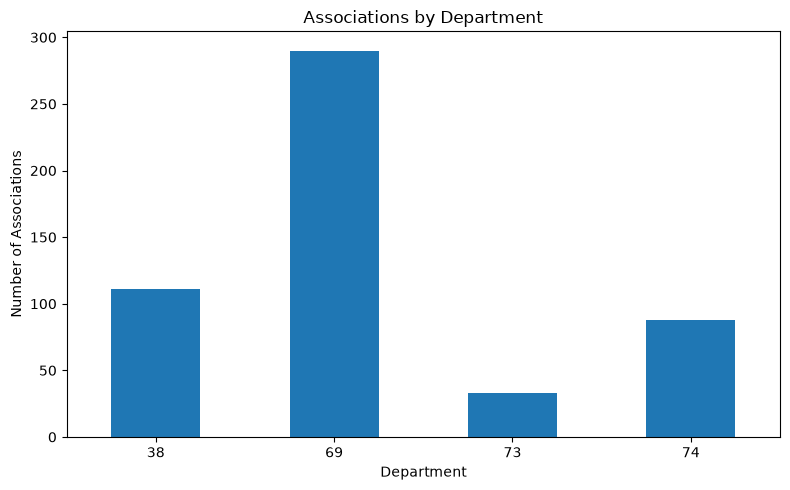

In [86]:
# Plot the number of associations by department
dept_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Associations by Department")
plt.xlabel("Department")
plt.ylabel("Number of Associations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [87]:
# Population by department (INSEE, 2023)
population_2023 = {
    "38": 1298990,
    "69": 1914667,
    "73": 448226,
    "74": 861158
}

# Associations per 100,000 inhabitants
assoc_per_100k = (
    dept_counts / pd.Series(population_2023) * 100000
).round(2)

display(assoc_per_100k)

department
38     8.55
69    15.15
73     7.36
74    10.22
dtype: double[pyarrow]

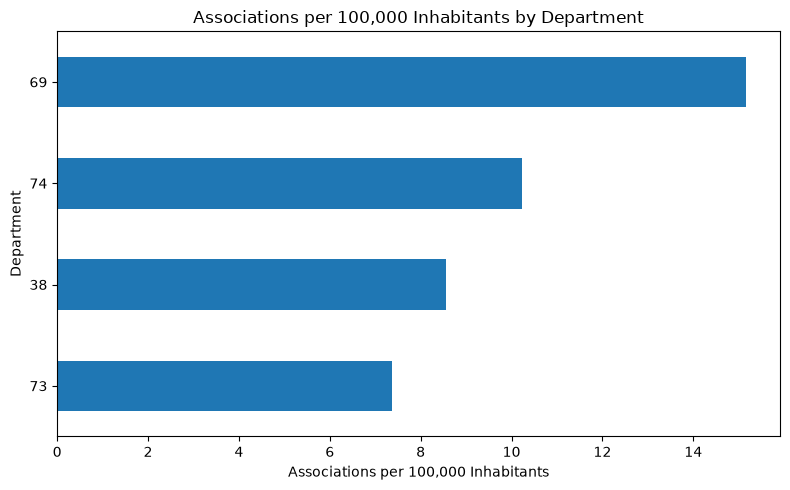

In [88]:
# Plot associations per 100,000 inhabitants
assoc_per_100k.sort_values().plot(kind="barh", figsize=(8, 5))

plt.title("Associations per 100,000 Inhabitants by Department")
plt.xlabel("Associations per 100,000 Inhabitants")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

In [89]:
# Count associations by theme
theme_counts = df_active[["VSS_VIF", "WOMEN_EQUALITY"]].sum()

display(theme_counts)

VSS_VIF           240
WOMEN_EQUALITY    352
dtype: int64

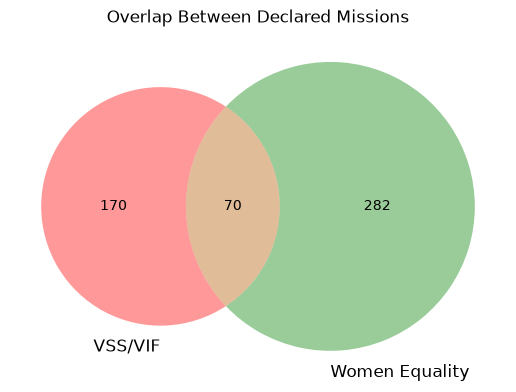

In [90]:
from matplotlib_venn import venn2

# Calculate the overlap between themes
vss_only = ((df_active["VSS_VIF"]) & (~df_active["WOMEN_EQUALITY"])).sum()
equality_only = ((~df_active["VSS_VIF"]) & (df_active["WOMEN_EQUALITY"])).sum()
both = (df_active["VSS_VIF"] & df_active["WOMEN_EQUALITY"]).sum()

# Plot the Venn diagram
venn2(
    subsets=(int(vss_only), int(equality_only), int(both)),
    set_labels=("VSS/VIF", "Women Equality")
)

plt.title("Overlap Between Declared Missions")
plt.show()

### Key Findings

- The dataset includes 522 administratively active RNA associations.
- Associations are classified into two themes: VSS/VIF and Women's Rights / Equality.
- Some associations belong to both categories.
- The thematic classification combines statutory objectives and documented activities.

These results do not represent an exhaustive list of operational services.

In [91]:
# Count associations by theme and department
themes_by_dept = df_active.groupby("department")[
    ["VSS_VIF", "WOMEN_EQUALITY"]
].sum()

display(themes_by_dept)

,VSS_VIF,WOMEN_EQUALITY
department,,
38,45,80
69,136,199
73,17,18
74,42,55


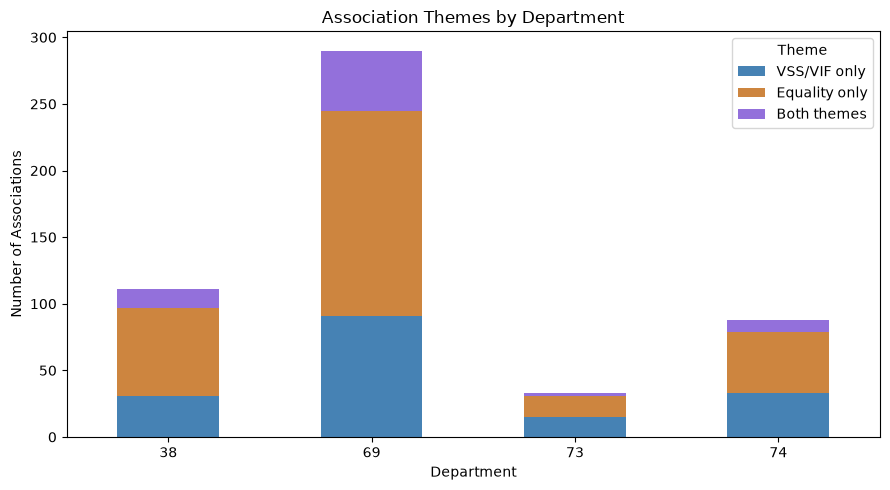

In [92]:
# Count exclusive and overlapping themes by department
themes_plot = pd.DataFrame({
    "VSS/VIF only": df_active["VSS_VIF"] & ~df_active["WOMEN_EQUALITY"],
    "Equality only": ~df_active["VSS_VIF"] & df_active["WOMEN_EQUALITY"],
    "Both themes": df_active["VSS_VIF"] & df_active["WOMEN_EQUALITY"]
}).groupby(df_active["department"]).sum()

# Plot stacked bars
themes_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["steelblue", "peru", "mediumpurple"]
)
plt.title("Association Themes by Department")
plt.xlabel("Department")
plt.ylabel("Number of Associations")
plt.xticks(rotation=0)
plt.legend(title="Theme")
plt.tight_layout()
plt.show()

In [93]:
# Check the overlap between themes in each department
display(themes_plot)

,VSS/VIF only,Equality only,Both themes
department,,,
38,31,66,14
69,91,154,45
73,15,16,2
74,33,46,9


In [94]:
# Identify associations matching both themes in Savoie
display(
    df_active.loc[
        (df_active["department"] == "73")
        & df_active["VSS_VIF"]
        & df_active["WOMEN_EQUALITY"],
        ["id", "titre", "objet"]
    ]
)

,id,titre,objet
472,W733004609,"PUISQUE JE PARS, JE SUIS LIBRE",développer l'information et favoriser l'accès ...
572,W732000525,SAVOIE DE FEMME,LE SOUTIEN DES FEMMES VICTIMES DE TOUTES FORME...


In [95]:
# Display the full declared mission
print(
    df_active.loc[
        df_active["id"] == "W733004609", "objet"
    ].iloc[0]
)

développer l'information et favoriser l'accès aux droits pour les femmes et le public en général en créant les services chargés d'accueillir, d'écouter, d'informer, d'orienter le public dans les domaines juridiques, professionnel, santé, vie relationnelle, ceci de façon confidentielle ; proposer, de développer et/ou de mettre en uvre toute action en matière de lutte contre les discriminations et toutes formes de violences faites aux femmes, quel que soit leur âge ; promouvoir l'égalité des chances entre les hommes et les femmes par le développement d'actions spécifiques liées à l'information et à la formation, devant particulièrement répondre à des besoins recensés lors de l'activité définie par la charte, relayer auprès du public, les mesures législatives et l'action des pouvoirs publics permettant la mise en uvre de l'égalité entre les femmes et les hommes ; travailler en partenariat avec les organismes compétents publics, para-publics, privés (ayant une vocation d'intérêt public) 

In [96]:
# Check creation dates
print(df_active["date_creat"].dtype)
print("Missing dates:", df_active["date_creat"].isna().sum())

display(df_active["date_creat"].head())

datetime64[us]
Missing dates: 0


0   1981-06-23
1   2007-04-03
2   1992-08-07
3   2007-06-11
4   2007-06-19
Name: date_creat, dtype: datetime64[us]

In [97]:
# Convert creation dates and extract the year
df_active["date_creat"] = pd.to_datetime(df_active["date_creat"], errors="coerce")
df_active["creation_year"] = df_active["date_creat"].dt.year

print("Invalid dates:", df_active["creation_year"].isna().sum())
display(df_active["creation_year"].describe())

Invalid dates: 0


count     522.000000
mean     2016.482759
std        11.896736
min      1953.000000
25%      2013.000000
50%      2020.000000
75%      2023.000000
max      2026.000000
Name: creation_year, dtype: float64

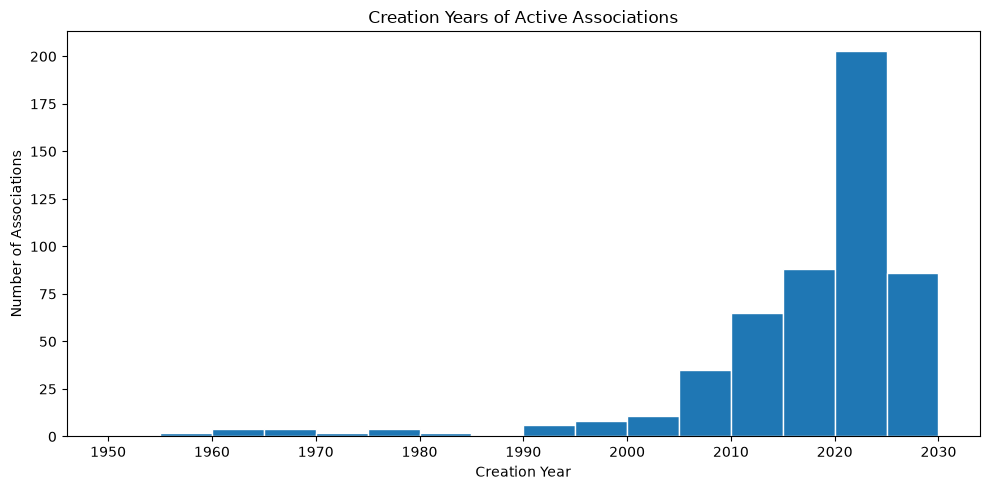

In [98]:
# Distribution of creation years
plt.figure(figsize=(10, 5))

plt.hist(
    df_active["creation_year"],
    bins=range(1950, 2031, 5),
    edgecolor="white"
)

plt.title("Creation Years of Active Associations")
plt.xlabel("Creation Year")
plt.ylabel("Number of Associations")
plt.xticks(range(1950, 2031, 10))
plt.tight_layout()
plt.show()

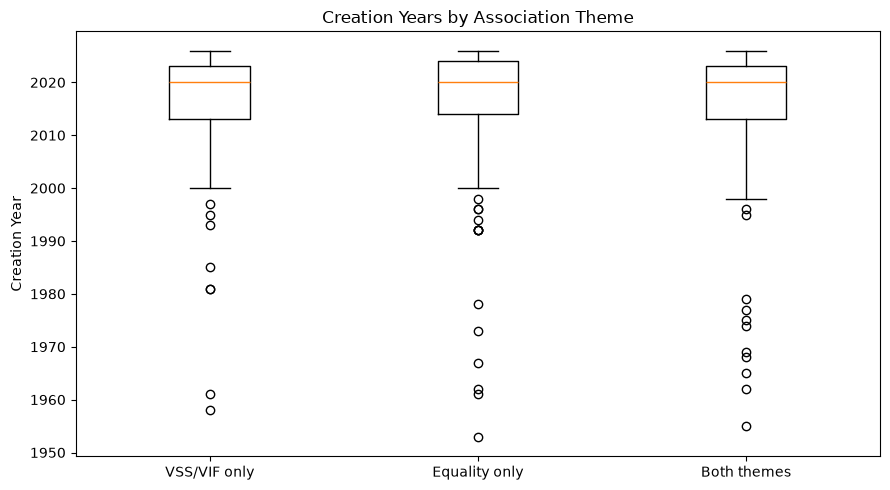

In [99]:
# Compare creation years by association theme
groups = [
    df_active.loc[df_active["VSS_VIF"] & ~df_active["WOMEN_EQUALITY"], "creation_year"].dropna(),
    df_active.loc[~df_active["VSS_VIF"] & df_active["WOMEN_EQUALITY"], "creation_year"].dropna(),
    df_active.loc[df_active["VSS_VIF"] & df_active["WOMEN_EQUALITY"], "creation_year"].dropna()
]

plt.figure(figsize=(9, 5))
plt.boxplot(groups, tick_labels=["VSS/VIF only", "Equality only", "Both themes"])

plt.title("Creation Years by Association Theme")
plt.ylabel("Creation Year")
plt.tight_layout()
plt.show()

In [100]:
# Count association creations by year since 2015
creations_by_year = (
    df_active["creation_year"]
    .value_counts()
    .sort_index()
)

display(creations_by_year.loc[2015:2026])

creation_year
2015     9
2016     9
2017    13
2018    24
2019    33
2020    39
2021    37
2022    48
2023    36
2024    43
2025    46
2026    40
Name: count, dtype: int64

In [101]:
# Count creations including dissolved associations
df_final_enriched["creation_year"] = pd.to_datetime(
    df_final_enriched["date_creat"], errors="coerce"
).dt.year

creations_all = (
    df_final_enriched["creation_year"]
    .value_counts()
    .sort_index()
)

display(creations_all.loc[2015:2026])

creation_year
2015    12
2016    10
2017    15
2018    27
2019    36
2020    41
2021    42
2022    49
2023    38
2024    44
2025    49
2026    42
Name: count, dtype: int64

In [102]:
# Compare yearly creations by association theme
themes_over_time = pd.DataFrame({
    "VSS/VIF only": df_final_enriched["VSS_VIF"] & ~df_final_enriched["WOMEN_EQUALITY"],
    "Equality only": ~df_final_enriched["VSS_VIF"] & df_final_enriched["WOMEN_EQUALITY"],
    "Both themes": df_final_enriched["VSS_VIF"] & df_final_enriched["WOMEN_EQUALITY"]
}).groupby(df_final_enriched["creation_year"]).sum()

display(themes_over_time.loc[2015:2026])

,VSS/VIF only,Equality only,Both themes
creation_year,,,
2015,4,8,0
2016,2,6,2
2017,5,9,1
2018,9,14,4
2019,5,22,9
2020,18,16,7
2021,14,25,3
2022,15,25,9
2023,14,21,3


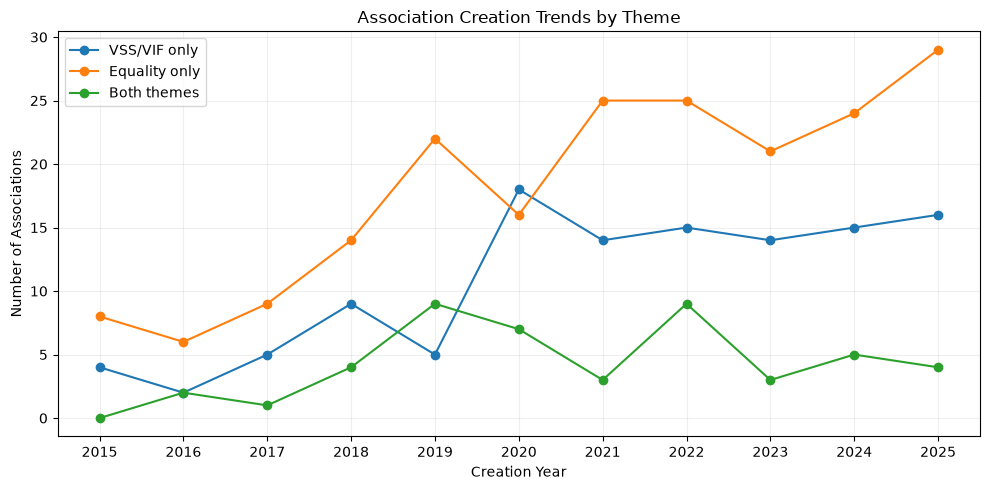

In [103]:
# Compare creation trends by theme
themes_over_time.loc[2015:2025].plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Association Creation Trends by Theme")
plt.xlabel("Creation Year")
plt.ylabel("Number of Associations")
plt.xticks(range(2015, 2026))
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### EDA Summary: Association Creation Trends

**Main findings**

The analysis covers associations with declared missions related to VSS/VIF and women's equality in four departments: Isère (38), Rhône (69), Savoie (73), and Haute-Savoie (74).

- The dataset includes **522 administratively active associations**. Their median creation year should be confirmed using the updated data.
- When dissolved associations are also included, recorded creations increase from **15 in 2017 to 27 in 2018**, reaching **49 in 2022 and 2025**.
- Associations classified as *Equality only* show higher annual creation numbers from 2018 onwards.
- Associations classified as *VSS/VIF only* show a noticeable increase in 2020, followed by relatively stable annual numbers.

**Possible explanations**

These trends occurred during a period of significant developments in women's rights in France:

- The #MeToo movement gained international attention in 2017.
- The Grenelle on domestic violence took place in 2019.
- The COVID-19 crisis began in 2020.

These events may have contributed to greater awareness and new associative initiatives. However, **our data cannot establish a causal relationship**.

**Limitations**

The analysis is based on a thematic selection of associations identified through their declared statutory missions and subsequent enrichment. It does not represent all associations created in the four departments.

Current thematic classifications may not reflect the associations' activities or priorities at the time of their creation.

The RNA provides administrative information, not a complete picture of operational services. Association headquarters do not necessarily represent their intervention areas.

**Strategic relevance for CIDFF**

The results suggest changes over time in the recorded creation of associations working on women's rights and gender-based violence.

For CIDFF, this raises two questions:

1. Which newer associations could become potential partners?
2. How can CIDFF strengthen its positioning and highlight its specific expertise in a changing associative environment?

Further analysis of emerging social issues, local services, and funding opportunities will help explore these questions.

In [104]:
# Explore Rhône associations covering both themes
rhone_both = df_active.loc[
    (df_active["department"] == "69")
    & df_active["VSS_VIF"]
    & df_active["WOMEN_EQUALITY"],
    ["titre", "objet"]
]

print("Associations covering both themes:", len(rhone_both))
display(rhone_both["titre"].sort_values().to_frame())

Associations covering both themes: 45


,titre
426,A VOIX EGALES
246,AGAPEGROUP'S (AG)
170,AGIR POUR LE GENRE
243,ALLIANCE DES FEMMES VERTUEUSES
256,APOLLINE
210,ARCENSIEL ASSOCIATION QUEER ET LGBTI+ DE L'ENS...
331,ASSOCIATION COLIBRI RÊVES AILES TOI
378,ASSOCIATION DE SERE ELEGANCE LUMIERE DE LYON (...
328,ASSOCIATION TCHADANTHROPUS
571,AU TAMBOUR !


In [105]:
# Check the themes assigned to key local associations
df_active.loc[
    (df_active["department"] == "69")
    & df_active["titre"].str.contains(
        "VIFFIL|MAS|TANDEM|PLANNING FAMILIAL",
        case=False,
        na=False
    ),
    ["titre", "VSS_VIF", "WOMEN_EQUALITY"]
]

,titre,VSS_VIF,WOMEN_EQUALITY
126,"MOUVEMENT FRANCAIS POUR LE PLANNING FAMILIAL, ...",True,True
128,"MOUVEMENT FRANÇAIS POUR LE PLANNING FAMILIAL, ...",False,True
573,VIFFIL-SOS FEMMES (VIOLENCES INTRA FAMILIALES ...,True,True
574,LE MAS (LE MOUVEMENT D'ACTION SOCIALE ),True,False


In [106]:
# Search for missing associations in the full RNA dataset
df_rna.loc[
    df_rna["titre"].str.contains(
        "VIFFIL|TANDEM|LE MAS|MOUVEMENT D'ACTION SOCIALE",
        case=False,
        na=False
    ),
    ["id", "titre", "objet", "position", "adrs_libcommune"]
]

,id,titre,objet,position,adrs_libcommune
1410,W381001413,CLUB CANIN SOUS LE MASSIF VERCUSIEN,Mettre en valeur les qualités de travail des c...,A,Veurey-Voroize
4480,W381004484,LE MAS ALTERNATIF DES SAVOIRS,"créer un lieu d'accueil, d'échange et de parta...",A,Saint-Lattier
5745,W381005749,AMICALE DES PERSONNELS DU COLLEGE LE MASSEGU VIF,participer aux évènements de la vie des adhére...,A,Vif
11327,W381011332,TANDEM-HANDICAPES-VALIDES,création de rencontres amicales et entraide en...,D,Grenoble
20656,W381023770,TANDEM,apporter son soutien aux activités de la secti...,A,Grenoble
26078,W381029238,LE MASQUE PRODUCTIONS,"1. création, diffusion et promotion de créatio...",A,Grenoble
28597,W382000422,TANDEM,"créer, gérer et exploiter tous services et tou...",A,Bourgoin-Jallieu
44728,W691052178,VIFFIL-SOS FEMMES (VIOLENCES INTRA FAMILIALES ...,Repondre aux besoins sociaux exigeant une inte...,A,Villeurbanne
46115,W691053567,LE MAS (LE MOUVEMENT D'ACTION SOCIALE ),"accueil, accompagnement et aide aux personnes ...",A,Lyon
49001,W691056459,LE MASQUE DE FER,"La promotion physique, intellectuelle et moral...",A,Lyon


In [107]:
# Inspect the missing associations
df_rna.loc[
    df_rna["id"].isin(["W691052178", "W691053567"]),
    ["titre", "objet"]
].apply(lambda row: print(f"\n{row['titre']}\n{row['objet']}"), axis=1)


VIFFIL-SOS FEMMES (VIOLENCES INTRA FAMILIALES FEMMES INFORMATIONS LIBERTÉS - SOS FEMMES)
Repondre aux besoins sociaux exigeant une intervention urgente écouter, informer, accompagner des personnes victimes

LE MAS (LE MOUVEMENT D'ACTION SOCIALE )
accueil, accompagnement et aide aux personnes en situation de victime, de souffrance psycho-sociale, de précarité ou d'exclusion ; recherche et sensibilisation sur les problématiques des publics concernés


44728    None
46115    None
dtype: object

In [108]:
# Search for other known local associations
df_rna.loc[
    df_rna["titre"].str.contains(
        "AMICALE DU NID|MOUVEMENT DU NID|ALURS|ÇA DÉMÉNAGE|CA DEMENAGE",
        case=False,
        na=False,
        regex=True
    ),
    ["id", "titre", "objet", "position", "adrs_libcommune"]
]

,id,titre,objet,position,adrs_libcommune
22256,W381025373,ÇA DÉMÉNAGE,prêter assistance aux femmes victimes de viole...,A,Grenoble


In [114]:
# Store SIRETs as text and remove the numeric suffix
associations_export["siret"] = (
    associations_export["siret"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
)

In [115]:
# Keep useful columns for SQL and Tableau
association_columns = [
    "id",
    "siret",
    "titre",
    "objet",
    "date_creat",
    "creation_year",
    "adrs_codeinsee",
    "adrs_libcommune",
    "postal_code",
    "department",
    "siteweb",
    "position",
    "VSS_VIF",
    "WOMEN_EQUALITY"
]

associations_export = df_active[association_columns].copy()

print(associations_export.shape)

(522, 14)


In [111]:
# Save the selected association data
associations_export.to_csv(
    "data/processed/territorial_associations.csv",
    index=False
)

print("Saved:", associations_export.shape)

Saved: (522, 14)


In [112]:
# Check the additional territorial datasets
print("Directory organizations:", df_directory_to_add.shape)
print("Healthcare services:", df_health_services.shape)

Directory organizations: (12, 7)
Healthcare services: (4, 21)


In [113]:
# Save directory organizations and healthcare services separately
df_directory_to_add.to_csv(
    "data/processed/directory_organizations.csv",
    index=False
)

df_health_services.to_csv(
    "data/processed/healthcare_services.csv",
    index=False
)

print("Saved: 12 directory organizations and 4 healthcare services")

Saved: 12 directory organizations and 4 healthcare services
